In [26]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as integ

In [27]:
eps=0.1
L=1
alpha = 1
beta = 2

In [28]:
def u_analy(x,eps):
    c1=(-np.exp(1/eps))/(1-np.exp(1/eps))
    c2=1/(1-np.exp(1/eps))
    return c1 + c2*np.exp(x/eps)+2*x

In [29]:
def g(x):
    return alpha *(1-x) +beta * x

In [30]:
def mat_ele(xi,xi_1,eps):
    hi=xi_1-xi
    eps_mat =np.array([[7,-8,1],[-8,16,-8],[1,-8,7]])/3
    lam_mat = np.array([[-3,4,-1],[-4,0,4],[1,-4,3]])/6
    f_mat = np.array([1,4,1])/6
    g_eps_mat = np.array([-1,0,1])

    Ah_Ti = eps_mat*eps/hi+lam_mat
    Fh_Ti = 2*hi*f_mat -(g_eps_mat+f_mat*hi)*(beta-alpha)

    return Ah_Ti,Fh_Ti

In [31]:
def a_g(xi,xi_1):
    hi = xi_1-xi
    return -hi*(alpha -beta)

In [32]:
def coef(l_x,eps):
    M=(len(l_x)-3)//2
    Ah=np.zeros((2*M+3,2*M+3)).reshape(2*M+3,2*M+3)
    Fh=np.zeros(2*M+3)
    for i in range(0,M+1):
        xi=l_x[2*i]
        xi_1=l_x[2*(i+1)]
        Ah_Ti,Fh_Ti=mat_ele(xi,xi_1,eps)
        Ah[2*i:2*i+3,2*i:2*i+3]+=Ah_Ti
        Fh[2*i:2*i+3]+=Fh_Ti

    Uh = np.zeros(2*M+3)
    Uh[1:2*M+2]= np.linalg.solve(Ah[1:2*M+2,1:2*M+2],Fh[1:2*M+2])
    return Uh

In [33]:
def graph_unif(L,M,eps):
    X=np.linspace(0,L,2*M+3)
    Uh=coef(X,eps)
    Ag = g(X)
    u_apprx = Ag + Uh

    u_ana=u_analy(X,eps)

    plt.plot(X,u_ana,label="solution analytique")
    plt.plot(X,u_apprx,"--",label="solution d'approximation")
    plt.xlabel("x")
    plt.ylabel("u(x)")
    plt.title("le schéma d'approximation de nombre d'intervalle "+str(M+1))
    plt.legend()
    plt.show()

In [34]:
l_M=[25,50,75,100,200]

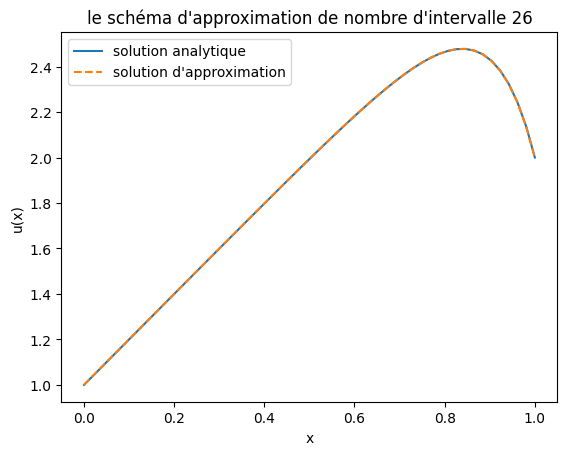

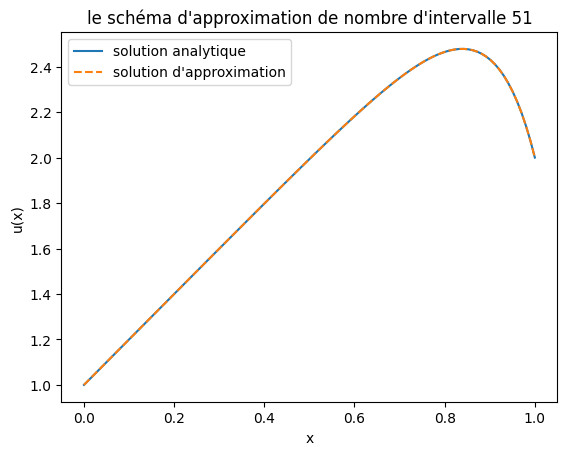

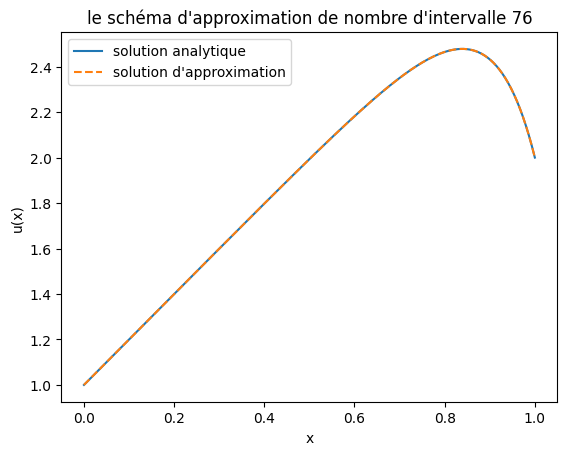

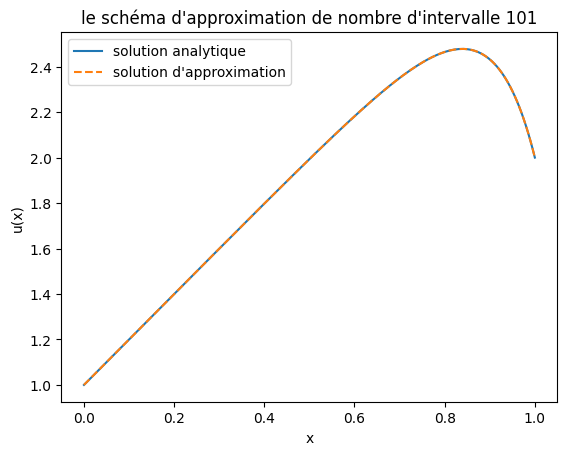

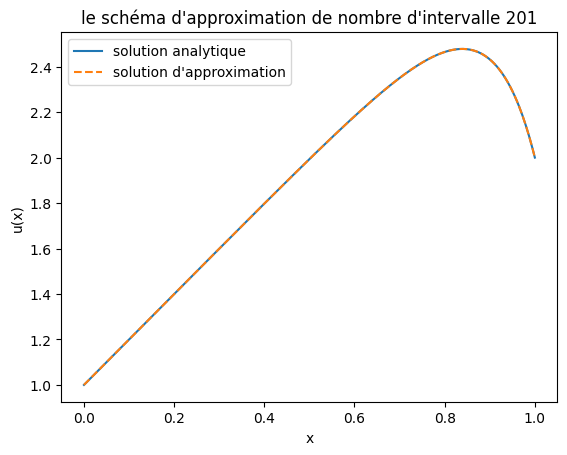

In [35]:
for m in l_M:
    graph_unif(L,m,eps)

In [36]:
def base_wi(x,xi,xi_1):
    hi = xi_1 - xi
    return (hi- 2 *(x-xi))*(hi-(x-xi))/hi**2
def base_wi_1(x,xi,xi_1):
    hi = xi_1 - xi
    return -(hi- 2 *(x-xi))*((x-xi))/hi**2
def base_wi_2(x,xi,xi_1):
    hi = xi_1 - xi
    return 4*(hi - (x-xi))*(x-xi)/hi**2

In [37]:
def diff(x,xi,xi_1,ui,ui2,ui_1):

    return(u_analy(x,eps)-(ui*base_wi(x,xi,xi_1)+ui2*base_wi_2(x,xi,xi_1)+ui_1*base_wi_1(x,xi,xi_1)+g(x)))**2

In [38]:
def erreur(l_x,u_ana,eps):
    M=(len(l_x)-3)//2
    err_tot = 0
    Uh = coef(l_x,eps)
    for i in range(0,M+1):
        xi=l_x[2*i]
        xi_1=l_x[2*(i+1)]
        Ui = Uh[2*i]
        Ui_1 = Uh[2*i+2]
        Ui2 = Uh[2*i+1]
        hi = xi_1-xi

        err_Ti = integ.quad(lambda x:(diff(x,xi,xi_1,Ui,Ui2,Ui_1)),xi,xi_1)[0]
        err_tot += err_Ti
    return np.sqrt(err_tot)

In [39]:
def graph_err(L,l_m,eps):
    l_err = []
    l_h=[]
    l_h3 = []
    for m in l_m:
        X=np.linspace(0,L,2*m+3)
        err=erreur(X,u_analy,eps)
        l_err.append(err)
        l_h3.append(L/(m+1)**3)
        l_h.append(L/(m+1))
    plt.plot(l_h,l_err,'--',label="norme 2 d'erreur d'approximation")
    plt.plot(l_h,l_h3,label="ordre h^3")
    plt.title("le graphe d'erreur d'approximation")
    plt.legend()
    plt.xlabel("le pas h")
    plt.ylabel("erreur")
    plt.show()

In [40]:
def graph_err_log(L,l_m,eps):
    l_err = []
    l_h=[]
    l_h3 = []
    for m in l_m:
        X=np.linspace(0,L,2*m+3)
        err=erreur(X,u_analy,eps)
        l_err.append(err)
        l_h3.append(L/(m+1)**3)
        l_h.append(L/(m+1))
    plt.loglog(l_h,l_err,'--',label="norme 2 d'erreur d'approximation")
    plt.loglog(l_h,l_h3,label="ordre h^3")
    plt.title("le graphe d'erreur d'approximation en log-log")
    plt.legend()
    plt.xlabel("le pas h")
    plt.ylabel("erreur")
    plt.show()

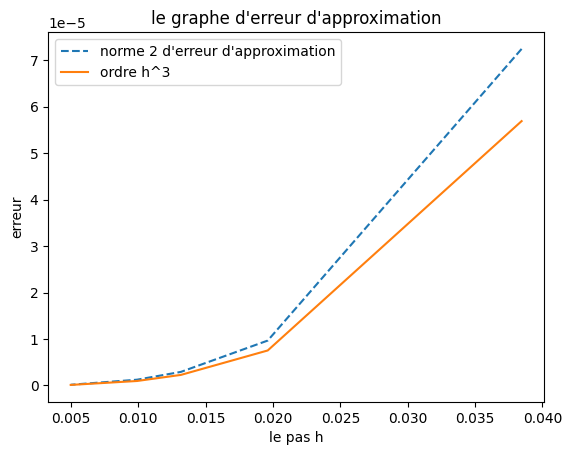

In [41]:
graph_err(L,l_M,eps)

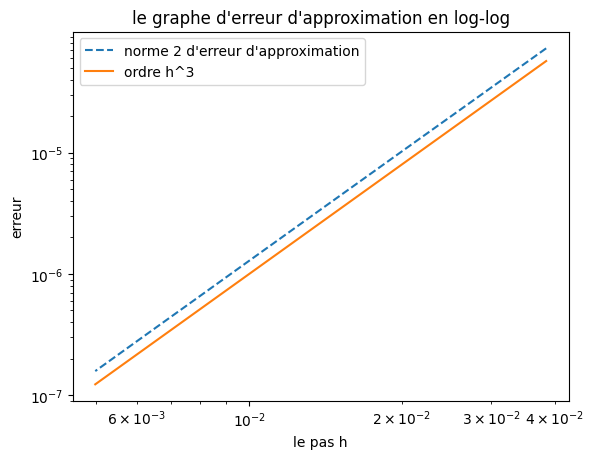

In [42]:
graph_err_log(L,l_M,eps)

In [43]:
def du(x,eps):
    c2=1/(1-np.exp(1/eps))
    return c2*np.exp(x/eps)/eps+2

In [44]:
def d_base_wi(x,xi,xi_1):
    hi = xi_1 - xi
    return (4*x-4*xi-3*hi)/hi**2
def d_base_wi_1(x,xi,xi_1):
    hi = xi_1 - xi
    return (4*x-4*xi-hi)/hi**2
def d_base_wi_2(x,xi,xi_1):
    hi = xi_1 - xi
    return (-8*x+8*xi+4*hi)/hi**2

In [45]:
def diff_d(x,xi,xi_1,ui,ui2,ui_1):

    return(du(x,eps)-(ui*d_base_wi(x,xi,xi_1)+ui2*d_base_wi_2(x,xi,xi_1)+ui_1*d_base_wi_1(x,xi,xi_1)+(beta-alpha)))**2

In [46]:
def erreur_d(l_x,u_ana,eps):
    M=(len(l_x)-3)//2
    err_tot = 0
    Uh = coef(l_x,eps)
    for i in range(0,M+1):
        xi=l_x[2*i]
        xi_1=l_x[2*(i+1)]
        Ui = Uh[2*i]
        Ui_1 = Uh[2*i+2]
        Ui2 = Uh[2*i+1]
        hi = xi_1-xi

        err_Ti = integ.quad(lambda x:(diff_d(x,xi,xi_1,Ui,Ui2,Ui_1)),xi,xi_1)[0]
        err_tot += err_Ti
    return np.sqrt(err_tot)

In [51]:
def graph_errd(L,l_m,eps):
    l_err = []
    l_h=[]
    l_h2 = []
    for m in l_m:
        X=np.linspace(0,L,2*m+3)
        err=erreur_d(X,u_analy,eps)
        l_err.append(err)
        l_h2.append(L/(m+1)**2)
        l_h.append(L/(m+1))
    np.asarray(l_h)
    plt.plot(l_h,l_err,'--',label="semi-norme H1 d'erreur d'approximation")
    plt.plot(l_h,l_h2,label="ordre h^2")
    plt.title("le graphe du semi-norme d'erreur d'approximation ")
    plt.legend()
    plt.xlabel("h")
    plt.ylabel("erreur")
    plt.show()

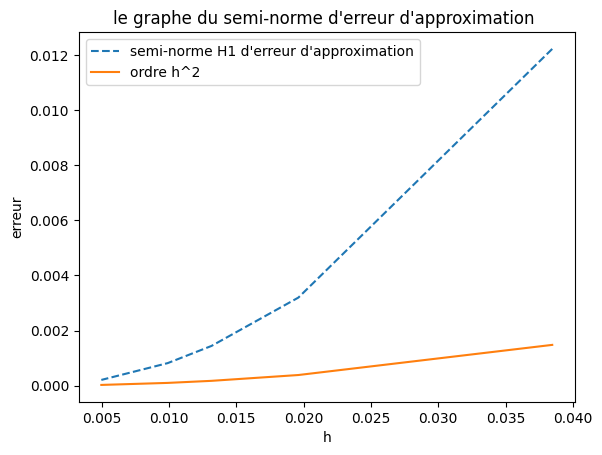

In [52]:
graph_errd(L,l_M,eps)

In [53]:
def graph_errd_log(L,l_m,eps):
    l_err = []
    l_h=[]
    l_h2 = []
    for m in l_m:
        X=np.linspace(0,L,2*m+3)
        err=erreur_d(X,u_analy,eps)
        l_err.append(err)
        l_h2.append(L/(m+1)**2)
        l_h.append(L/(m+1))
    np.asarray(l_h)
    plt.loglog(l_h,l_err,'--',label="semi-norme H1 d'erreur d'approximation")
    plt.loglog(l_h,l_h2,label="ordre h^2")
    plt.title("le graphe du semi-norme d'erreur d'approximation en log-log")
    plt.legend()
    plt.xlabel("h")
    plt.ylabel("erreur")
    plt.show()

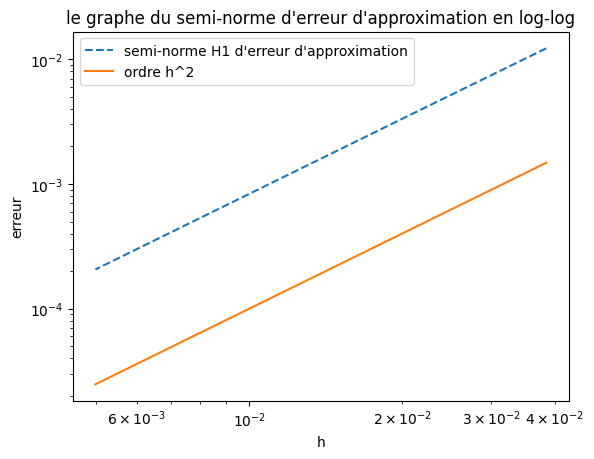

In [54]:
graph_errd_log(L,l_M,eps)